# a sanity check on an air layer to account for flight height

In [36]:
import torch

from anemone.experiment import Loop, Receiver, Forward
import matplotlib.pyplot as plt
import numpy as np

c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:237: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma, dtype=torch.complex128)[:,None,None]
c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:238: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, dtype=torch.complex128)[:,None,None]


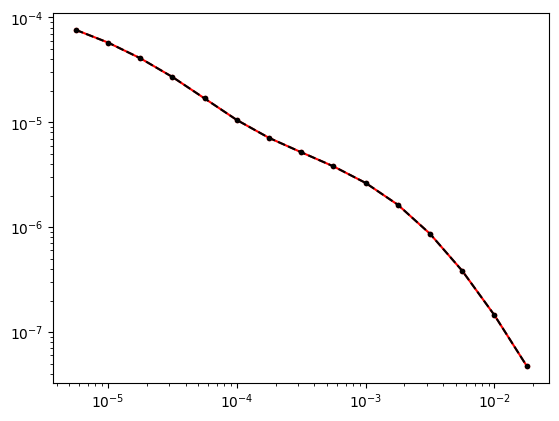

In [47]:
lp = Loop.circle(6, z=20)
rx = Receiver(z=25)
times = np.logspace(-5,-2, 31)

sigma = torch.tensor([0.1, 1, 0.1])
thick = torch.tensor([40, 40])

fwr = Forward(lp, rx, times)
t1,dbdt1 = fwr(sigma, thick)


lp = Loop.circle(6, z=0)
rx = Receiver(z=5)
times = np.logspace(-5,-2, 31)

sigma = torch.tensor([0., 0.1, 1, 0.1])
thick = torch.tensor([20, 40, 40])

fwr = Forward(lp, rx, times)
t2,dbdt2 = fwr(sigma, thick)


# Plot sounding
fig,ax = plt.subplots()
ax.loglog(t1.numpy(), np.abs(dbdt1.numpy().real), 'r.-', label='normal_setup')
ax.loglog(t2.numpy(), np.abs(dbdt2.numpy().real), 'k.--', label='air-layer')

In [48]:
print(np.abs(dbdt1.numpy())-np.abs(dbdt2.numpy()))

[ 4.74338450e-19 -5.55653613e-19 -6.36968776e-19 -2.20228566e-19
 -3.79470760e-19 -5.01443505e-19  1.74488787e-19  4.15893177e-19
 -1.47383733e-19 -9.14795583e-20  1.14349448e-20 -2.83967796e-19
 -2.13875819e-19 -5.69629657e-19 -9.07013468e-19]


so appears to be at the machine precision level so that is wonderful.